# ⚽ Football Field Detection — YOLOv8 Training (Google Colab)

This notebook trains a YOLOv8 model on a **football-field-detection** dataset (Roboflow format) stored in Google Drive.

**Pipeline:**
1. Mount Google Drive
2. Install Ultralytics (YOLOv8)
3. Point to dataset (`data.yaml`) in Drive
4. Train for 100 epochs
5. Validate + visualize results
6. Run inference on a test image
7. Save best weights back to Drive

> ⚠️ Before running: **Runtime → Change runtime type → GPU (T4 or better)**

## 1. Check GPU

In [1]:
!nvidia-smi

Sat Jul 11 10:59:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Install Ultralytics (YOLOv8)

In [3]:
!pip install -q ultralytics

import ultralytics
ultralytics.checks()

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.7/112.6 GB disk)


## 4. Set Dataset Path

Edit `DATASET_DIR` below to point to the folder in your Drive that contains `data.yaml`, `train/`, `valid/`, `test/` (each with `images/` and `labels/` subfolders — exactly as shown in your screenshot).

Example: if the folder is at `My Drive/Datasets/football-field-detection`, then:
```
DATASET_DIR = "/content/drive/MyDrive/Datasets/football-field-detection"
```

In [4]:
# >>> EDIT THIS PATH <<<
DATASET_DIR = "/content/drive/MyDrive/football-field-detection"

DATA_YAML = f"{DATASET_DIR}/data.yaml"

import os
assert os.path.exists(DATA_YAML), f"data.yaml not found at {DATA_YAML}. Fix DATASET_DIR above."
print("Found data.yaml at:", DATA_YAML)

Found data.yaml at: /content/drive/MyDrive/football-field-detection/data.yaml


## 5. Inspect `data.yaml`

Roboflow's exported `data.yaml` usually has relative paths (`train: ../train/images`). We rewrite it with **absolute paths** so training works reliably from any working directory in Colab.

In [5]:
import yaml

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

print("Original data.yaml contents:")
print(data_cfg)

# Detect whether this is a KEYPOINT/POSE dataset (Roboflow field-detection exports
# are keypoint datasets: class xc yc w h  x1 y1 v1  x2 y2 v2 ...)
IS_POSE = "kpt_shape" in data_cfg
print("\nIS_POSE:", IS_POSE)
if IS_POSE:
    print("kpt_shape:", data_cfg["kpt_shape"])

# Rewrite with absolute paths to train/valid/test images folders
data_cfg["train"] = f"{DATASET_DIR}/train/images"
data_cfg["val"]   = f"{DATASET_DIR}/valid/images"
if os.path.exists(f"{DATASET_DIR}/test/images"):
    data_cfg["test"] = f"{DATASET_DIR}/test/images"

FIXED_YAML = "/content/data.yaml"
with open(FIXED_YAML, "w") as f:
    yaml.dump(data_cfg, f)

print("\nFixed data.yaml written to:", FIXED_YAML)
print(data_cfg)

Original data.yaml contents:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'kpt_shape': [32, 3], 'flip_idx': [24, 25, 26, 27, 28, 29, 22, 23, 21, 17, 18, 19, 20, 13, 14, 15, 16, 9, 10, 11, 12, 8, 6, 7, 0, 1, 2, 3, 4, 5, 31, 30], 'nc': 1, 'names': ['pitch'], 'roboflow': {'workspace': 'roboflow-jvuqo', 'project': 'football-field-detection-f07vi', 'version': 18, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/roboflow-jvuqo/football-field-detection-f07vi/dataset/18'}}

IS_POSE: True
kpt_shape: [32, 3]

Fixed data.yaml written to: /content/data.yaml
{'train': '/content/drive/MyDrive/football-field-detection/train/images', 'val': '/content/drive/MyDrive/football-field-detection/valid/images', 'test': '/content/drive/MyDrive/football-field-detection/test/images', 'kpt_shape': [32, 3], 'flip_idx': [24, 25, 26, 27, 28, 29, 22, 23, 21, 17, 18, 19, 20, 13, 14, 15, 16, 9, 10, 11, 12, 8, 6, 7, 0, 1, 2, 3, 4, 5, 31, 30], 'nc': 1, 'names': ['pitch'], 

## 6. Sanity Check — Count Images & Labels

In [6]:
for split in ["train", "valid", "test"]:
    img_dir = f"{DATASET_DIR}/{split}/images"
    lbl_dir = f"{DATASET_DIR}/{split}/labels"
    if os.path.exists(img_dir):
        n_img = len([f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        n_lbl = len([f for f in os.listdir(lbl_dir) if f.endswith('.txt')]) if os.path.exists(lbl_dir) else 0
        print(f"{split:6s} -> images: {n_img:5d} | labels: {n_lbl:5d}")
    else:
        print(f"{split:6s} -> NOT FOUND ({img_dir})")

train  -> images:   255 | labels:   255
valid  -> images:    34 | labels:    34
test   -> images:    28 | labels:    28


## 7. Preview a Sample Image + Bounding Boxes

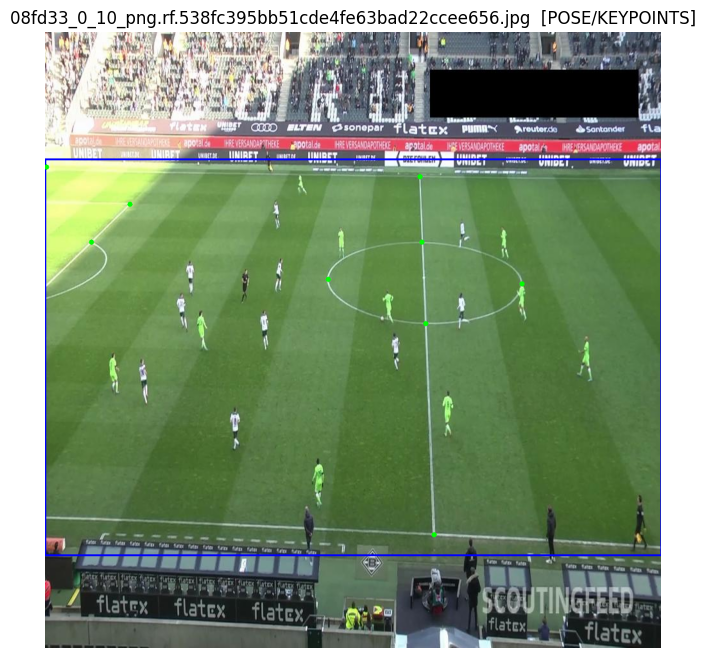

In [7]:
import cv2
import matplotlib.pyplot as plt
import glob
import numpy as np

sample_images = sorted(glob.glob(f"{DATASET_DIR}/train/images/*.jpg")) + \
                 sorted(glob.glob(f"{DATASET_DIR}/train/images/*.png"))

if sample_images:
    img_path = sample_images[0]
    lbl_path = img_path.replace("images", "labels").rsplit(".", 1)[0] + ".txt"

    img = cv2.imread(img_path)
    h, w = img.shape[:2]

    if os.path.exists(lbl_path):
        with open(lbl_path) as f:
            for line in f:
                vals = list(map(float, line.split()))
                cls = int(vals[0])
                rest = vals[1:]

                if IS_POSE:
                    # Format: xc yc w h  x1 y1 v1  x2 y2 v2  ...
                    xc, yc, bw, bh = rest[:4]
                    x1 = int((xc - bw / 2) * w); y1 = int((yc - bh / 2) * h)
                    x2 = int((xc + bw / 2) * w); y2 = int((yc + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

                    kpts = rest[4:]
                    for i in range(0, len(kpts), 3):
                        kx, ky, v = kpts[i], kpts[i+1], kpts[i+2]
                        if v > 0:  # 0 = not labeled, skip
                            px, py = int(kx * w), int(ky * h)
                            color = (0, 255, 0) if v == 2 else (0, 165, 255)  # visible=green, occluded=orange
                            cv2.circle(img, (px, py), 4, color, -1)
                elif len(rest) == 4:
                    # Standard bbox format: xc yc w h
                    xc, yc, bw, bh = rest
                    x1 = int((xc - bw / 2) * w); y1 = int((yc - bh / 2) * h)
                    x2 = int((xc + bw / 2) * w); y2 = int((yc + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                else:
                    # Polygon format: x1 y1 x2 y2 x3 y3 ...
                    pts = np.array(rest, dtype=np.float32).reshape(-1, 2)
                    pts[:, 0] *= w; pts[:, 1] *= h
                    pts = pts.astype(np.int32)
                    cv2.polylines(img, [pts], isClosed=True, color=(0, 255, 0), thickness=2)

    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(os.path.basename(img_path) + ("  [POSE/KEYPOINTS]" if IS_POSE else ""))
    plt.show()
else:
    print("No sample images found to preview.")

## 8. Train YOLOv8 (100 Epochs)

Using `yolov8n.pt` (nano, fastest) as the pretrained base. Swap to `yolov8s.pt` / `yolov8m.pt` for higher accuracy at the cost of speed if needed.

In [8]:
from ultralytics import YOLO

# Automatically pick a pretrained base model:
# - Keypoint/pose dataset (kpt_shape in data.yaml)  -> yolov8n-pose.pt
# - Plain bbox detection dataset                     -> yolov8n.pt
BASE_WEIGHTS = "yolov8n-pose.pt" if IS_POSE else "yolov8n.pt"
print("Using base weights:", BASE_WEIGHTS)

model = YOLO(BASE_WEIGHTS)

results = model.train(
    data=FIXED_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=30,          # early stopping if no improvement for 30 epochs
    project="/content/runs",
    name="football_field_detection",
    exist_ok=True,
    plots=True,
    save=True,
    device=0               # GPU
)

Using base weights: yolov8n-pose.pt
Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=football_field_detection, nbs=64, nms=False, opset=Non

## 9. Validate Best Model

In [9]:
BEST_WEIGHTS = "/content/runs/football_field_detection/weights/best.pt"

best_model = YOLO(BEST_WEIGHTS)
metrics = best_model.val(data=FIXED_YAML)

print("Box mAP50:", metrics.box.map50)
print("Box mAP50-95:", metrics.box.map)

if IS_POSE and hasattr(metrics, "pose"):
    print("Pose mAP50:", metrics.pose.map50)
    print("Pose mAP50-95:", metrics.pose.map)

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-pose summary (fused): 82 layers, 3,670,259 parameters, 0 gradients, 10.9 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.2 ms, read: 44.9±18.6 MB/s, size: 117.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/football-field-detection/valid/labels.cache... 34 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 34/34 6.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2s/it 3.5s
                   all         34         34      0.998          1      0.995      0.991      0.998          1      0.995      0.783
Speed: 14.7ms preprocess, 32.1ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /content/runs/pose/val
Box mA

## 10. Visualize Training Curves

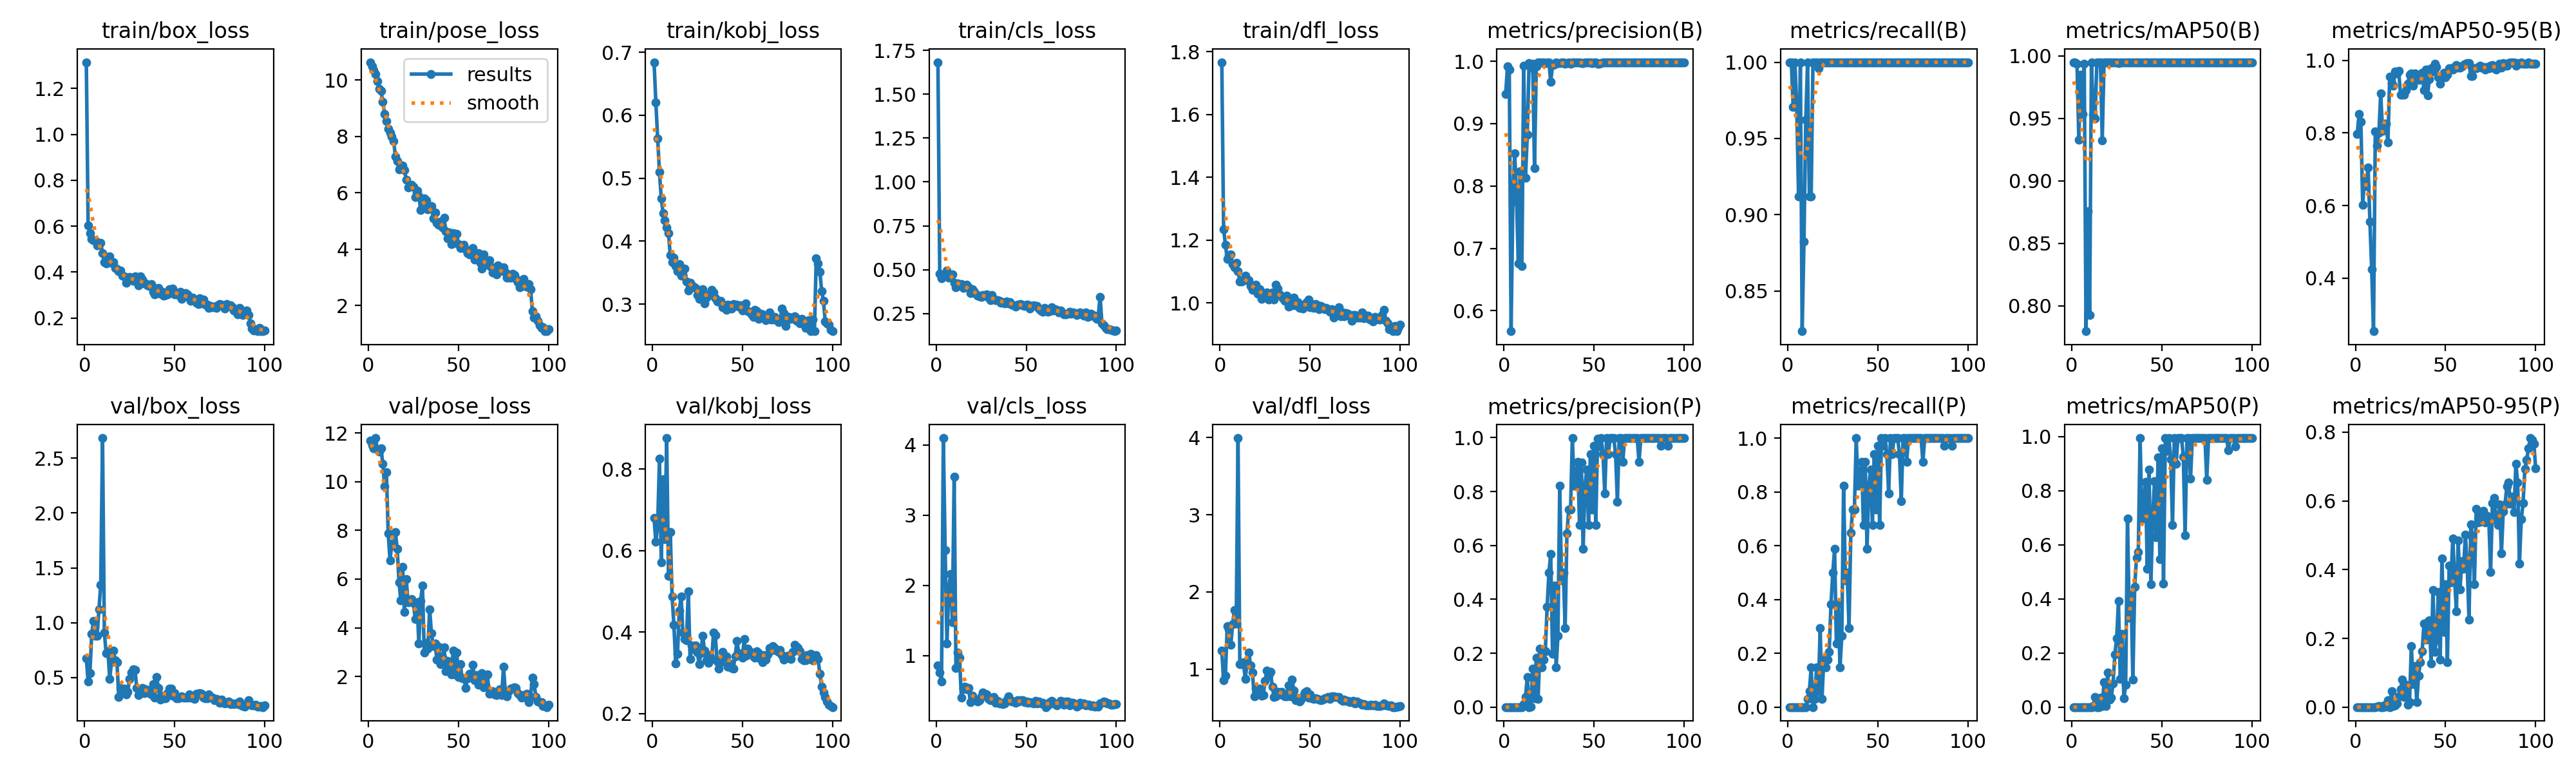

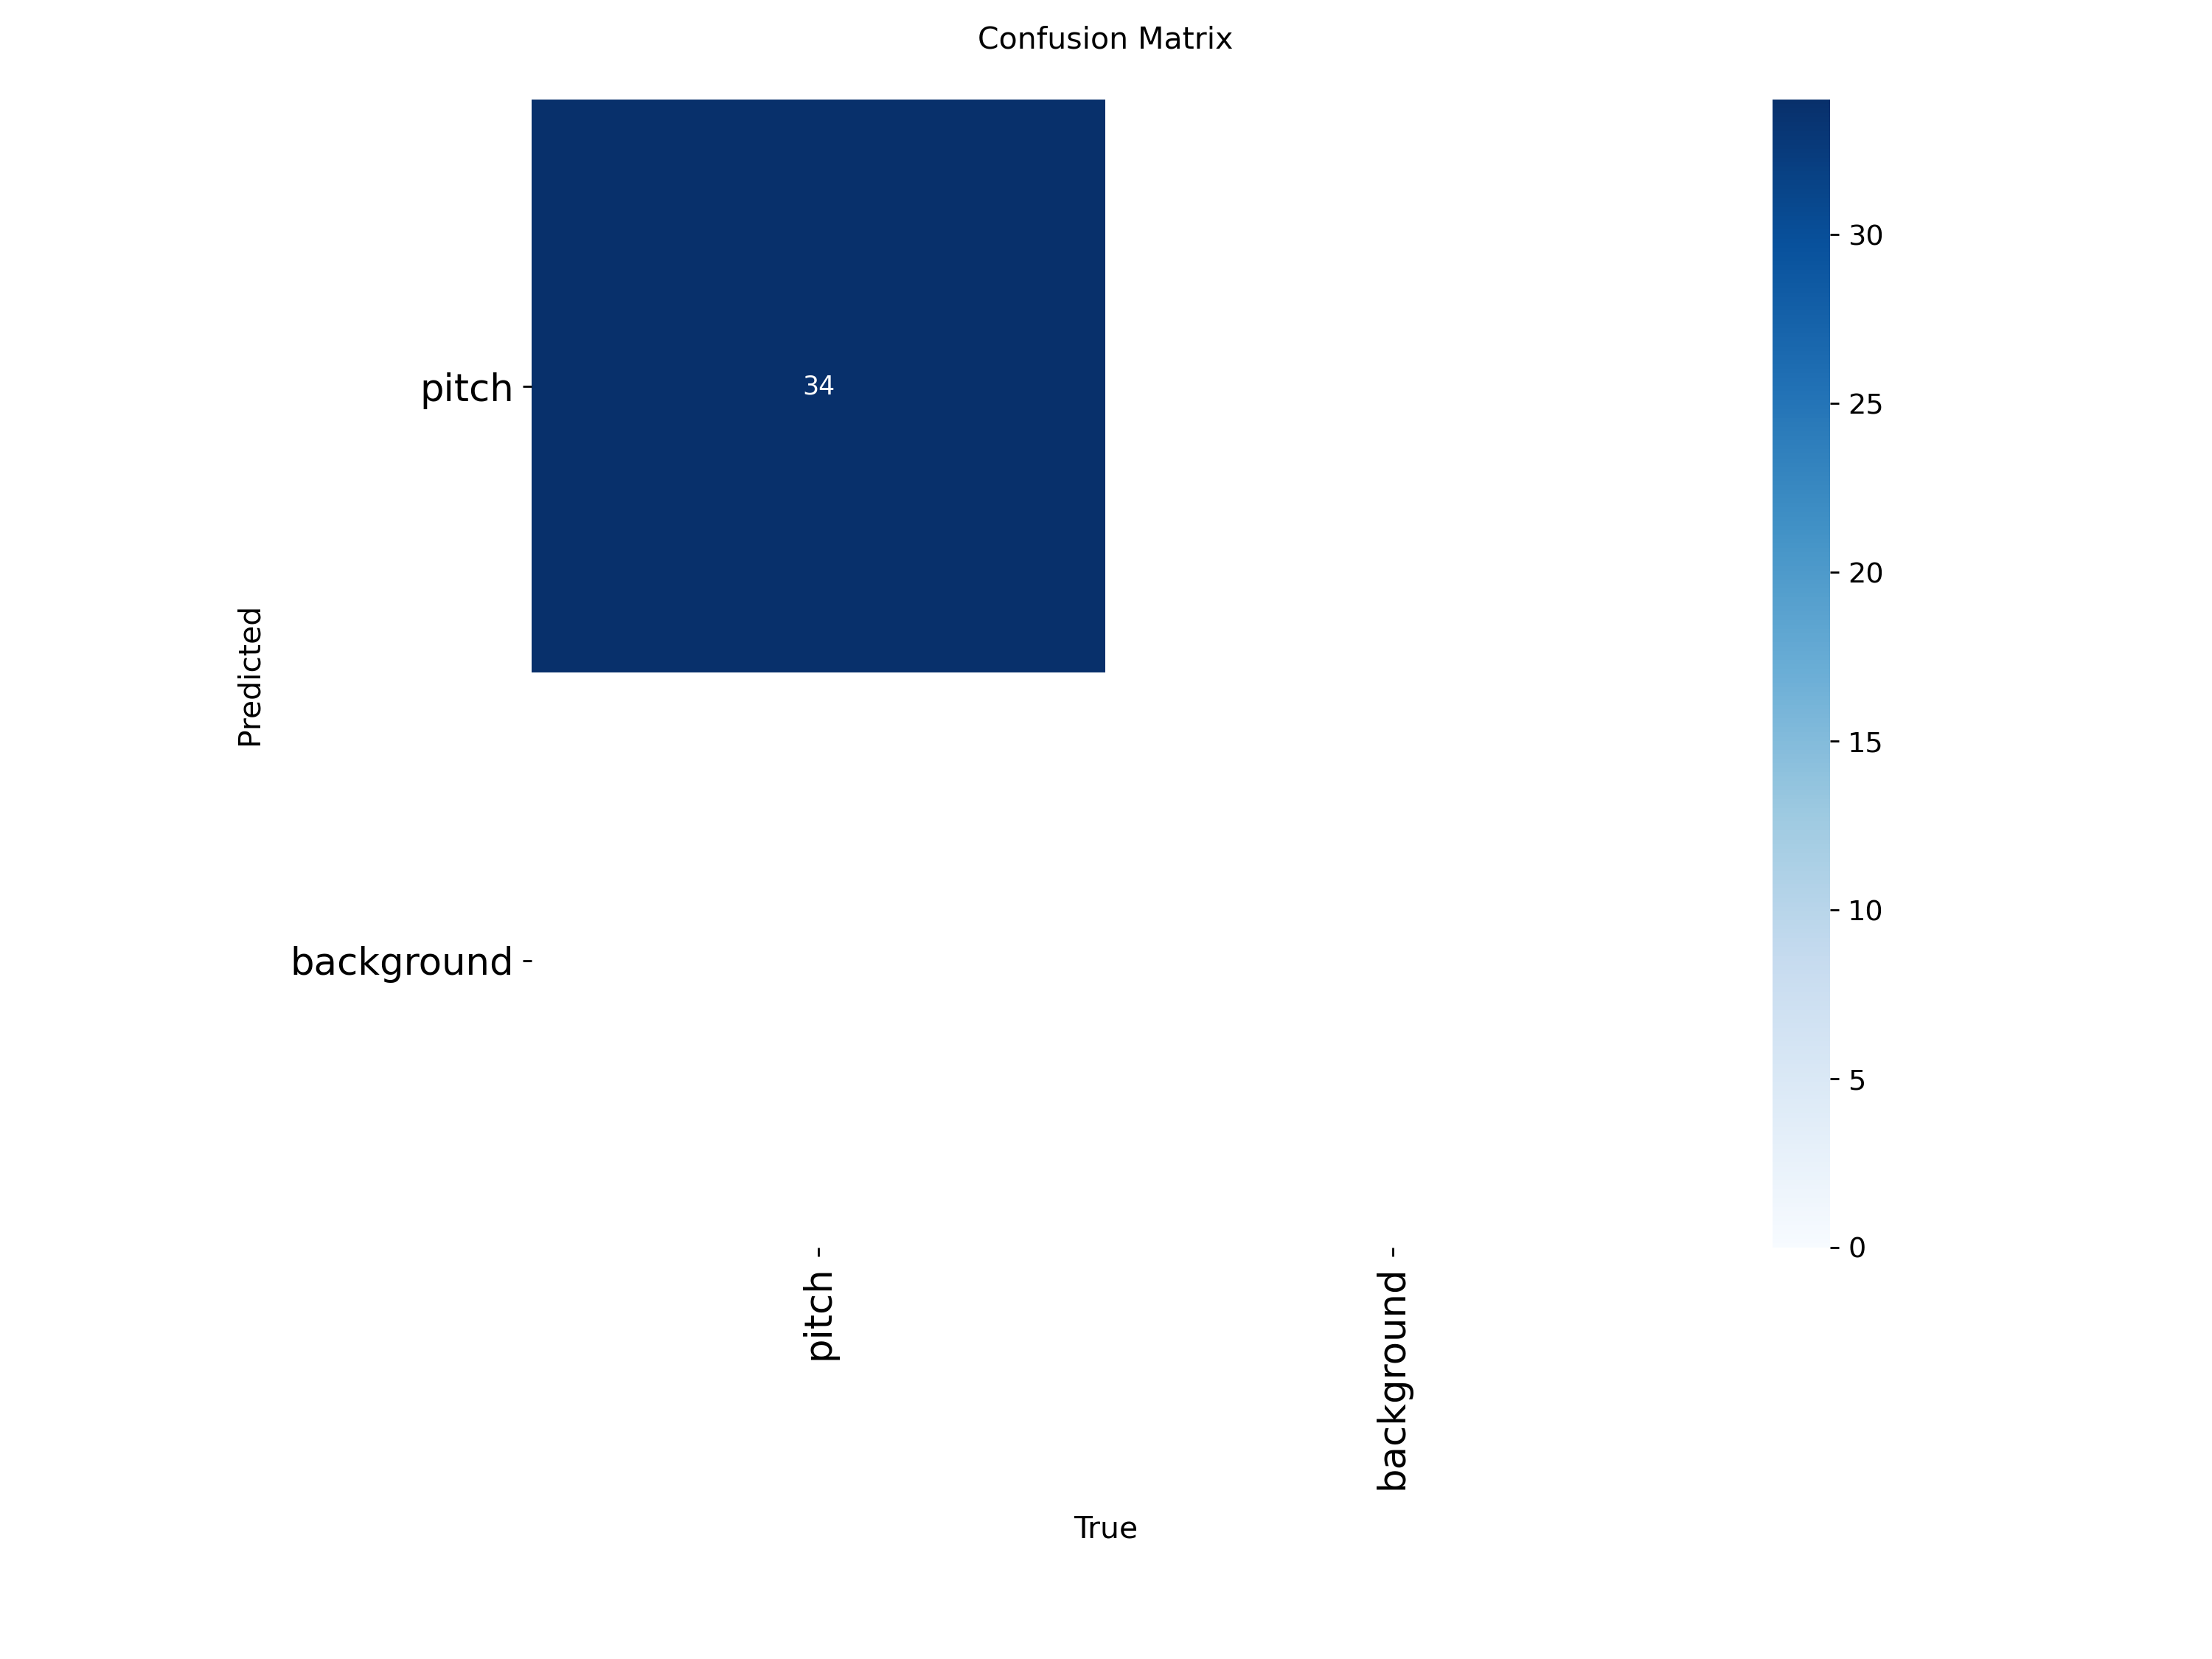

In [10]:
from IPython.display import Image, display

results_png = "/content/runs/football_field_detection/results.png"
confusion_png = "/content/runs/football_field_detection/confusion_matrix.png"

if os.path.exists(results_png):
    display(Image(filename=results_png, width=900))
if os.path.exists(confusion_png):
    display(Image(filename=confusion_png, width=700))

## 11. Run Inference on Test Set

In [11]:
test_images_dir = f"{DATASET_DIR}/test/images"

if os.path.exists(test_images_dir):
    pred_results = best_model.predict(
        source=test_images_dir,
        imgsz=640,
        conf=0.25,
        save=True,
        project="/content/runs",
        name="football_field_predictions",
        exist_ok=True
    )
    print("Predictions saved to /content/runs/football_field_predictions")
else:
    print("No test/images folder found — skipping inference step.")


image 1/28 /content/drive/MyDrive/football-field-detection/test/images/08fd33_2_9_png.rf.21b38ce5a95b5c38493db73c2adf656f.jpg: 640x640 1 pitch, 8.9ms
image 2/28 /content/drive/MyDrive/football-field-detection/test/images/08fd33_4_11_png.rf.d1cfe8fcc086f5fd5890f642df7ca55f.jpg: 640x640 1 pitch, 8.9ms
image 3/28 /content/drive/MyDrive/football-field-detection/test/images/08fd33_4_3_png.rf.a35582c6f261af4aec5a04a390c9ba4e.jpg: 640x640 1 pitch, 9.7ms
image 4/28 /content/drive/MyDrive/football-field-detection/test/images/08fd33_9_2_png.rf.bb85a42a79de01d73a84f054b34d7e5e.jpg: 640x640 1 pitch, 8.8ms
image 5/28 /content/drive/MyDrive/football-field-detection/test/images/0a2d9b_2_2_png.rf.bf97f45c42055c3d81fa8f3b2682e628.jpg: 640x640 1 pitch, 8.9ms
image 6/28 /content/drive/MyDrive/football-field-detection/test/images/121364_3_1_png.rf.0faf3dd76c49f1cc912dbda825b7ebfd.jpg: 640x640 1 pitch, 8.9ms
image 7/28 /content/drive/MyDrive/football-field-detection/test/images/121364_3_7_png.rf.321135aab

### Preview a Few Predictions

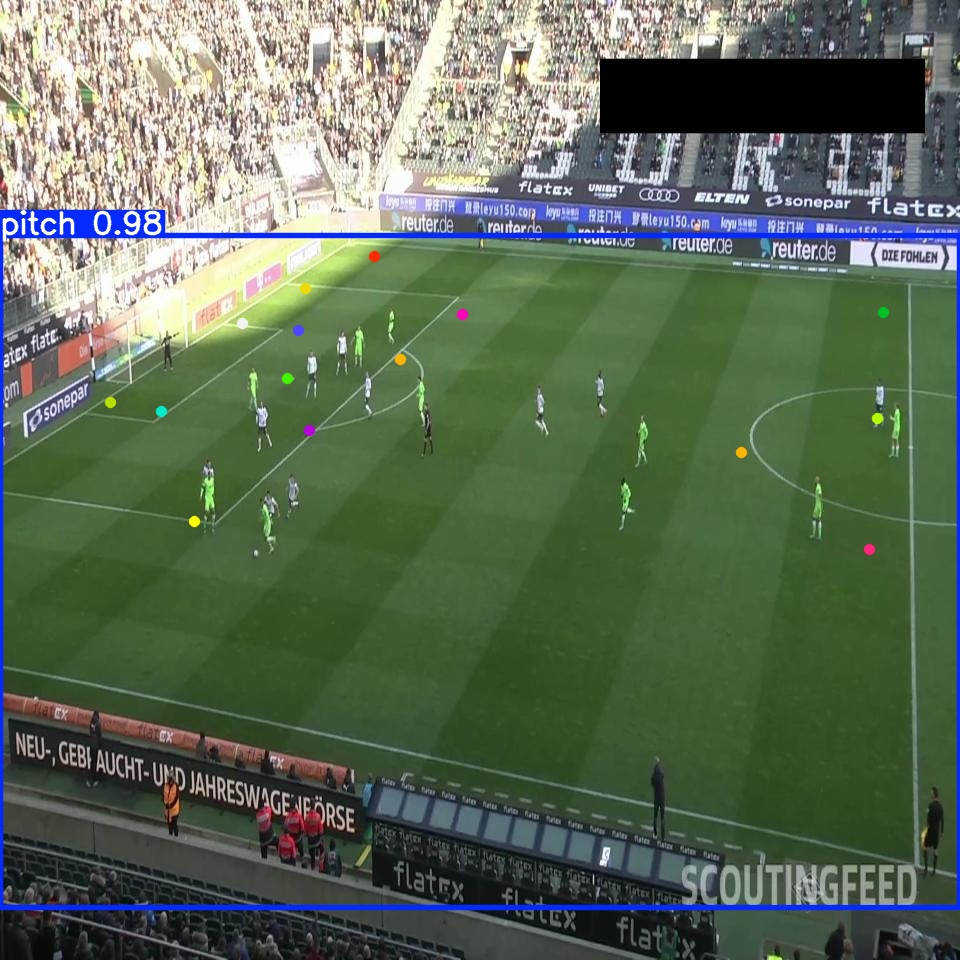

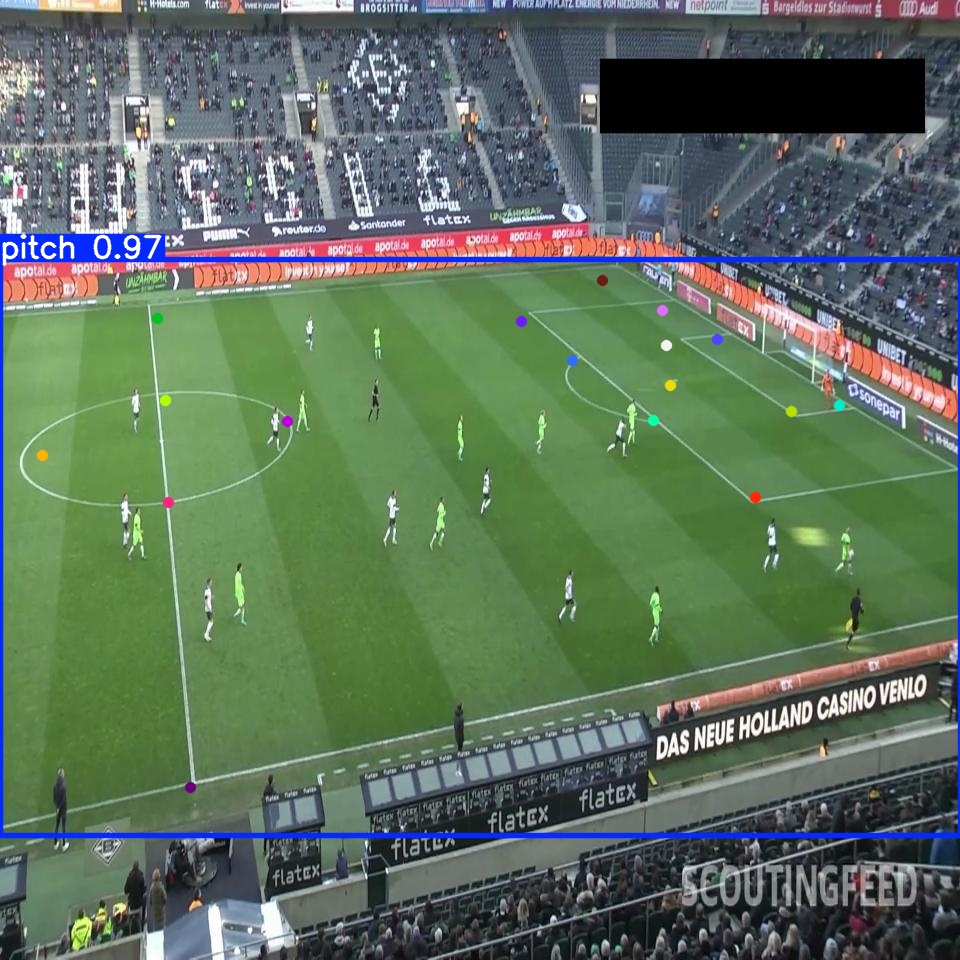

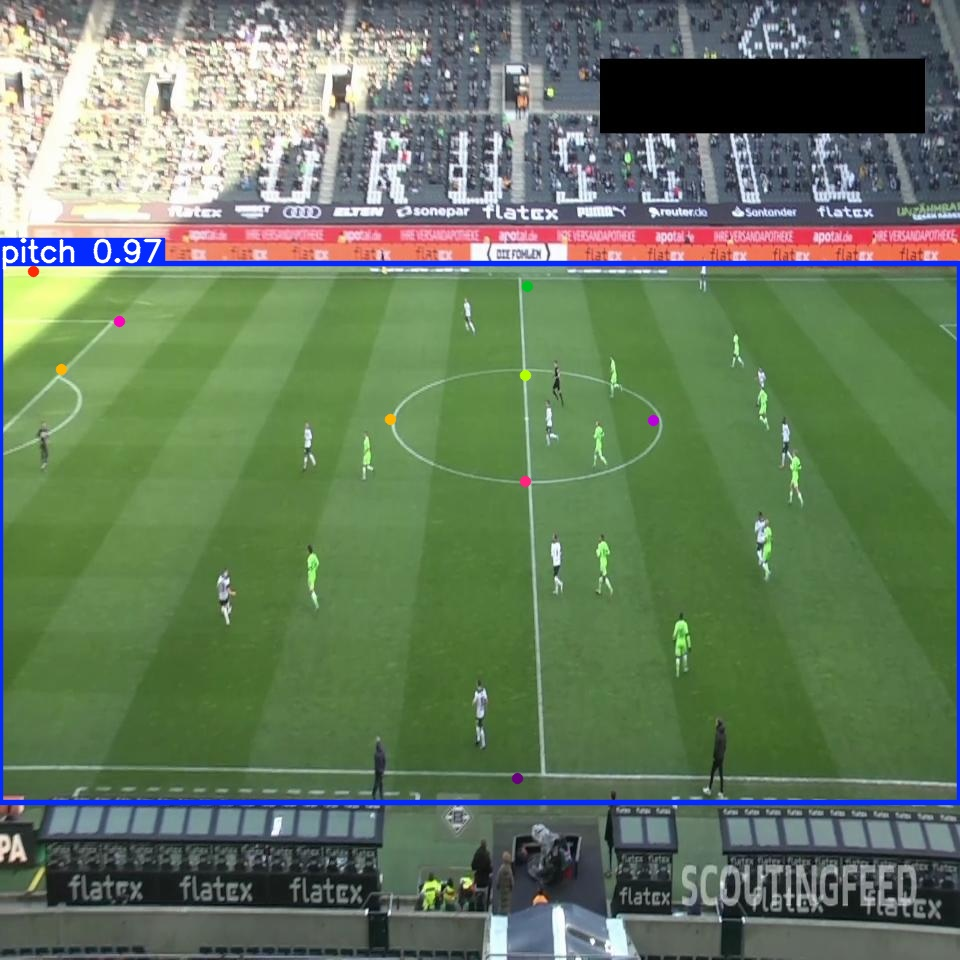

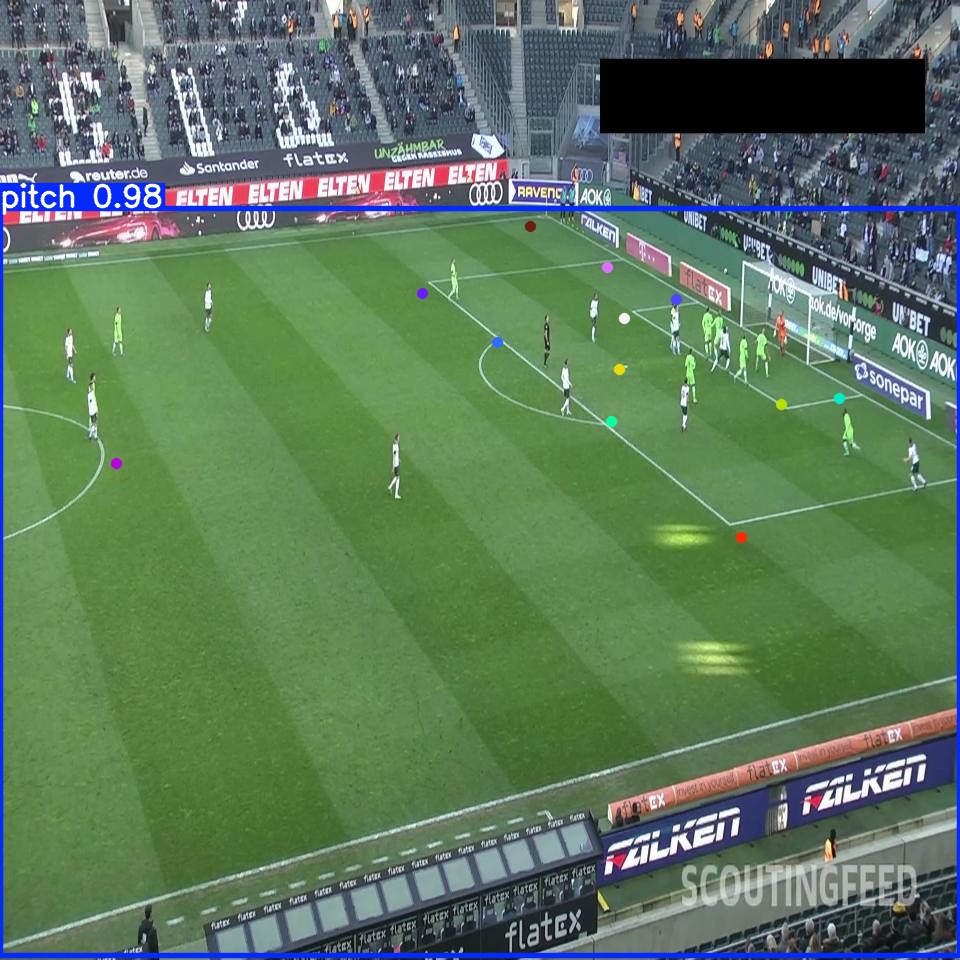

In [12]:
pred_dir = "/content/runs/football_field_predictions"
pred_files = sorted(glob.glob(f"{pred_dir}/*.jpg"))[:4]

for p in pred_files:
    display(Image(filename=p, width=600))

## 12. Save Trained Weights Back to Google Drive

In [13]:
import shutil

SAVE_DIR = f"{DATASET_DIR}/training_results"
os.makedirs(SAVE_DIR, exist_ok=True)

# Copy best & last weights
shutil.copy("/content/runs/football_field_detection/weights/best.pt", f"{SAVE_DIR}/best.pt")
shutil.copy("/content/runs/football_field_detection/weights/last.pt", f"{SAVE_DIR}/last.pt")

# Copy full results folder (plots, metrics, logs)
results_dest = f"{SAVE_DIR}/runs_football_field_detection"
if os.path.exists(results_dest):
    shutil.rmtree(results_dest)
shutil.copytree("/content/runs/football_field_detection", results_dest)

print("Saved weights + results to:", SAVE_DIR)

Saved weights + results to: /content/drive/MyDrive/football-field-detection/training_results


## 13. (Optional) Export to ONNX / TFLite / etc.

In [ ]:
# Uncomment the format you need

# best_model.export(format="onnx")
# best_model.export(format="tflite")
# best_model.export(format="torchscript")

---
### Notes
- `yolov8n.pt` = nano (fastest, lowest accuracy). Use `yolov8s.pt`/`yolov8m.pt`/`yolov8l.pt` for better accuracy if your GPU/time budget allows.
- `patience=30` enables early stopping — training may finish before 100 epochs if validation metrics plateau. Set `patience=100` (or remove it) to force the full 100 epochs regardless.
- If you hit CUDA out-of-memory errors, lower `batch` (e.g. 8 or 4).
- Best weights are at `/content/runs/football_field_detection/weights/best.pt` and are also copied to your Drive at the end.